By Alex Furlich. ChatGPT was used to help generate code. However all written answers did not use AI.

Best max_depth from cross-validation: 10
Best mean cross-validation accuracy: 0.7516


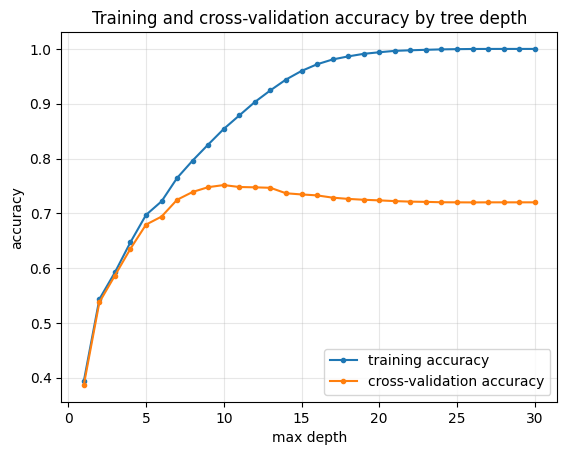

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from decision_tree import DecisionTreeClassifier
from sklearn.model_selection import KFold

X_test = np.load("data/X_test.npy")
X_train = np.load("data/X_train.npy")
y_test = np.load("data/y_test.npy")
y_train = np.load("data/y_train.npy")

folds = 5
max_max_depth = 30
depths = np.arange(1, max_max_depth + 1)
kf = KFold(n_splits=folds, shuffle=True, random_state=0)

training_accuracies = np.zeros((folds, depths.size))
validation_accuracies = np.zeros((folds, depths.size))

# Loop over all of the hyperparameter settings
for depth_index, max_depth in enumerate(depths):
    # Evaluate each depth on every validation fold.
    for fold_index, (train_index, val_index) in enumerate(kf.split(X_train)):
        X_tr, X_val = X_train[train_index, :], X_train[val_index, :]
        y_tr, y_val = y_train[train_index], y_train[val_index]

        tree = DecisionTreeClassifier(max_depth=int(max_depth))
        tree.fit(X_tr, y_tr)
        training_accuracies[fold_index, depth_index] = tree.score(X_tr, y_tr)
        validation_accuracies[fold_index, depth_index] = tree.score(X_val, y_val)

# Average accuracy across the folds
training_accuracy_avg = np.mean(training_accuracies, axis=0)
validation_accuracy_avg = np.mean(validation_accuracies, axis=0)
best_depth_index = np.argmax(validation_accuracy_avg)
best_depth = depths[best_depth_index]
best_validation_accuracy = validation_accuracy_avg[best_depth_index]
print(f'Best max_depth from cross-validation: {best_depth}')
print(f'Best mean cross-validation accuracy: {best_validation_accuracy:.4f}')

plt.plot(depths, training_accuracy_avg, '.-', label='training accuracy')
plt.plot(depths, validation_accuracy_avg, '.-', label='cross-validation accuracy')
plt.xlabel('max depth')
plt.ylabel('accuracy')
plt.title('Training and cross-validation accuracy by tree depth')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Hyperparameter Tuning**

In the above code we are tuning the max-depth hyperparameter using a 5 fold cross-validation. The range 1-30 was picked because by 30 the trees are consistently hitting a training accuracy of 1 meaning they have perfectly fit the training data. We can see using cross-validation that the best results/the highest ratio of correct predictions on average across the 5 folds are when max-depth is set to 10.


**Underfitting and Overfitting**

Underfitting begings at the start of the graph. When the max depth is set to very low values the decision tree does not have the flexibility it needs to reflect the patterns present in the data set. As the max depth grows we can see that training accuracy consistently improves until it hits a perfect accuracy of 1. However if we only followed training accuracy we would likely over fit. Once the max depth passes 10 the cross-validation accuracy indicates that we actually lose accuracy as we increase model flexibility. This is because the model is overfitting to the training data and does not do as good a job reflecting what new data that is not in the training data will be. 

Our goal here is to find the sweet spot where the model have the flexibility needed to accurately reflect the trends in the data without overshooting.

Test accuracy at best depth (10): 0.7740
Classification report:
                           precision    recall  f1-score   support

         0: 0-190 rentals       0.83      0.78      0.80       434
       1: 191-504 rentals       0.69      0.73      0.71       451
      2: 505-1065 rentals       0.76      0.72      0.74       429
3: more than 1065 rentals       0.83      0.86      0.85       438

                 accuracy                           0.77      1752
                macro avg       0.78      0.77      0.77      1752
             weighted avg       0.78      0.77      0.77      1752

Confusion matrix:
[[340  79  13   2]
 [ 66 329  44  12]
 [  3  53 310  63]
 [  2  18  41 377]]


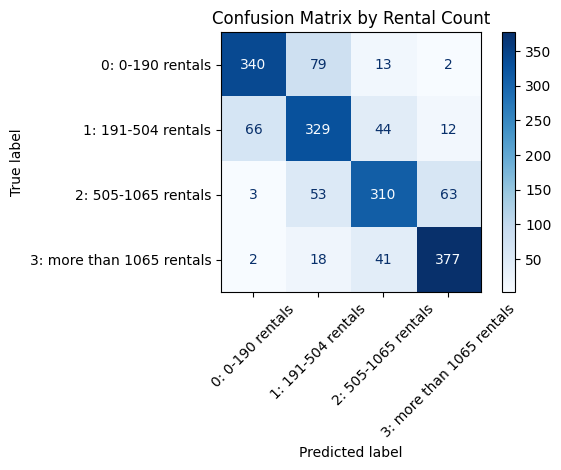

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from decision_tree import DecisionTreeClassifier
from sklearn.model_selection import KFold
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay


X_test = np.load("data/X_test.npy")
X_train = np.load("data/X_train.npy")
y_test = np.load("data/y_test.npy")
y_train = np.load("data/y_train.npy")

# Train the final model using the best depth from cross-validation
final_tree = DecisionTreeClassifier(max_depth=int(10))
final_tree.fit(X_train, y_train)

# Predict the held-out test data
y_test_predict = final_tree.predict(X_test)

test_accuracy = final_tree.score(X_test, y_test)
print(f'Test accuracy at best depth (10): {test_accuracy:.4f}')

# Use the rental-count ranges as the class labels in the report and plot.
class_labels = np.arange(4)
class_names = [
    "0: 0-190 rentals",
    "1: 191-504 rentals",
    "2: 505-1065 rentals",
    "3: more than 1065 rentals"
]

# Report class-level precision, recall, and F1 score.
print("Classification report:")
print(classification_report(
    y_test,
    y_test_predict,
    labels=class_labels,
    target_names=class_names,
    zero_division=0
))

# Force a 4x4 matrix for the four rental-count classes.
matrix = confusion_matrix(y_test, y_test_predict, labels=class_labels)

print("Confusion matrix:")
print(matrix)

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=class_names
)
display.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix by Rental Count")
plt.tight_layout()
plt.show()


**Classification Error Analysis**

The above code runs a classification report on the decision tree with a max-depth of 10, Showing us the precision, recall and F1 score for each of the classifications. It also creates a 4x4 Confusion matrix for us to reference. 

**Discussion** 

When it comes to analyzing the accuracy of this classification I would recommend using the F1 score. Since we are predicting bike rentals the most likely application of the predictions may be expected income of a rental shop/preperation required in the shop depending on the day. There isn't a specific need to value recall over precision thus F1 allows us to balance both equally. 

In the end our cross validation predicted an accuracy of 0.7516. However the accuracy (% correct predictions) when applied to the test set was 0.774 and the average F1 score when applied to test data was 0.775. Its also worth noting that the confusion matrix shows us that incorrect preditions are most often off by 1 level instead of on the other end of the spectrum. Or more simply when the actual number of rentals is 0-190 it is extremely rare that the tree labels it as a day with more than 1065 rentals. This is a fact that we cannot see with the F1 score alone. 

So in general my model has a predicted accuracy of 0.774. And it is predicted that when it missclassifies it will do so with a value adjacent to the correct predition not a value on the opposite end of the spectrum. That will not always be true but it will be correct in the vast majority of misclassifications. 

In [2]:
import numpy as np
from decision_tree import DecisionTreeClassifier, impurity, weighted_impurity

# Feature names in the same order as the columns in X_train.
feature_names = [
    "Hour",
    "Temperature (C)",
    "Humidity (%)",
    "Wind speed (m/s)",
    "Visibility (10m)",
    "Dew point temperature (C)",
    "Solar Radiation (MJ/m2)",
    "Rainfall (mm)",
    "Snowfall (cm)",
    "Season",
    "Holiday",
    "Functioning Day"
]

X_train = np.load("data/X_train.npy")
y_train = np.load("data/y_train.npy")

# Fit the tree independently at the selected depth.
analysis_depth = 10
analysis_tree = DecisionTreeClassifier(max_depth=analysis_depth)
analysis_tree.fit(X_train, y_train)

# Analyze which features were used as split points and how helpful they were.
num_features = X_train.shape[1]
split_counts = np.zeros(num_features, dtype=int)
total_gini_gains = np.zeros(num_features)
split_thresholds = [[] for _ in range(num_features)]


def collect_split_statistics(node):
    if node.split is None:
        return

    feature_index = node.split.dim
    split_counts[feature_index] += 1
    split_thresholds[feature_index].append(node.split.pos)
    total_gini_gains[feature_index] += (
        impurity(node.y) - weighted_impurity(node.split)
    )

    collect_split_statistics(node.left)
    collect_split_statistics(node.right)


collect_split_statistics(analysis_tree._root)
feature_importances = analysis_tree.feature_importances_
average_gini_gains = np.divide(
    total_gini_gains,
    split_counts,
    out=np.zeros(num_features),
    where=split_counts != 0
)

feature_order = np.argsort(feature_importances)[::-1]
name_width = max(len(feature_names[i]) for i in feature_order)

print(f"Feature split analysis for tree depth {analysis_depth}:")
print(
    f"{'rank':>4} | {'feature':<{name_width}} | {'importance':>10} | "
    f"{'split count':>11} | {'total Gini gain':>15} | {'average Gini gain':>17} |"
)
for rank, feature_index in enumerate(feature_order, start=1):
    print(
        f"{rank:>4} | {feature_names[feature_index]:<{name_width}} | "
        f"{feature_importances[feature_index]:>10.4f} | "
        f"{split_counts[feature_index]:>11} | "
        f"{total_gini_gains[feature_index]:>15.4f} | "
        f"{average_gini_gains[feature_index]:>17.4f} |"
    )


Feature split analysis for tree depth 10:
rank | feature                   | importance | split count | total Gini gain | average Gini gain |
   1 | Hour                      |     0.2921 |          71 |         11.5176 |            0.1622 |
   2 | Temperature (C)           |     0.2786 |          86 |         13.5647 |            0.1577 |
   3 | Humidity (%)              |     0.0901 |          50 |          7.4523 |            0.1490 |
   4 | Solar Radiation (MJ/m2)   |     0.0863 |          21 |          1.9249 |            0.0917 |
   5 | Functioning Day           |     0.0765 |           5 |          0.3612 |            0.0722 |
   6 | Season                    |     0.0516 |          16 |          1.1161 |            0.0698 |
   7 | Rainfall (mm)             |     0.0452 |          10 |          0.6932 |            0.0693 |
   8 | Visibility (10m)          |     0.0245 |          32 |          3.8834 |            0.1214 |
   9 | Wind speed (m/s)          |     0.0202 |          3

**Parameter Discussion**
These are the attributes that were used by the decision tree. The importance gives us the amount the attribute contributed to total weighted gini impurity reduction. So Hours importance of 0.2921 means that it contrubited to about 29.21% of the trees total weighted gini improvement. Intrestingly it seems the tree heavily relies on Hour and Temperature as they both have significantly higher importance scores compared to the other attributes. Meanwhile things like Snowfall and Holiday have a very small impact on the tree. 